<a href="https://colab.research.google.com/github/Lalsmed/EcommerceDemandPrediction/blob/main/Ejercicio_analisis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
df = pd.read_excel('online_retail_II.xlsx')

print(df.head())


  Invoice StockCode                          Description  Quantity  \
0  536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1  536365     71053                  WHITE METAL LANTERN         6   
2  536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3  536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4  536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  Price  Customer ID         Country  
0  2010-01-12 08:26:00   2.55      17850.0  United Kingdom  
1  2010-01-12 08:26:00   3.39      17850.0  United Kingdom  
2  2010-01-12 08:26:00   2.75      17850.0  United Kingdom  
3  2010-01-12 08:26:00   3.39      17850.0  United Kingdom  
4  2010-01-12 08:26:00   3.39      17850.0  United Kingdom  


Datos limpios y listos. Filas restantes: 397925


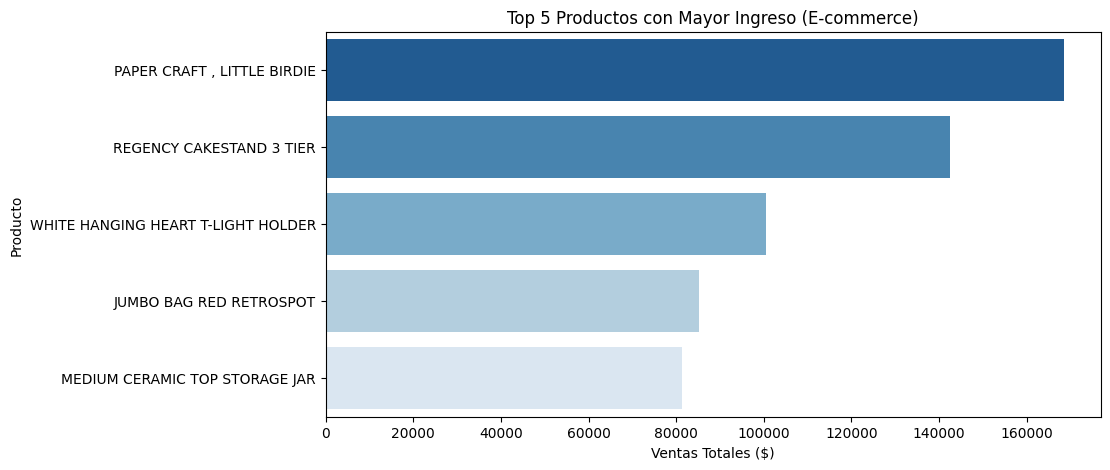

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Limpieza básica (Asumiendo nombres estándar de columnas del dataset Online Retail)
# Eliminamos filas con valores nulos en el ID de cliente o descripción
df = df.dropna(subset=['Customer ID', 'Description'])

# 2. Filtrar devoluciones o cancelaciones (en este dataset suelen empezar con 'C' o tener cantidad negativa)
if 'Invoice' in df.columns:
    df = df[~df['Invoice'].astype(str).str.startswith('C')]
df = df[df['Quantity'] > 0]

# 3. Convertir la fecha a formato datetime para poder hacer análisis temporal
# (Asegúrate de que el nombre de tu columna de fecha sea 'InvoiceDate', cámbialo si es distinto)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Crear una columna de Ventas Totales (Cantidad * Precio)
df['TotalSales'] = df['Quantity'] * df['Price']

print("Datos limpios y listos. Filas restantes:", len(df))

# Agrupar por producto y sumar las ventas totales, luego tomar el top 5
top_products = df.groupby('Description')['TotalSales'].sum().reset_index()
top_products = top_products.sort_values(by='TotalSales', ascending=False).head(5)

# Crear el gráfico visual
plt.figure(figsize=(10, 5))
sns.barplot(data=top_products, x='TotalSales', y='Description', hue='Description', palette='Blues_r', legend=False)
plt.title('Top 5 Productos con Mayor Ingreso (E-commerce)')
plt.xlabel('Ventas Totales ($)')
plt.ylabel('Producto')
plt.show()

Error Absoluto Medio (MAE) del modelo: $304758.44


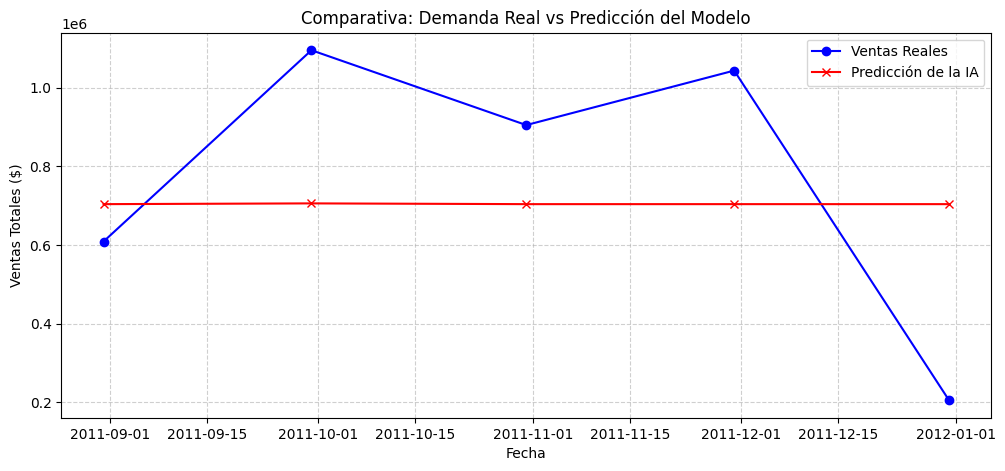

In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1. Agrupar las ventas totales por mes
# (Nota: usamos 'ME' para fin de mes en versiones recientes de pandas, si te da error cambia 'ME' por 'M')
df_ts = df.set_index('InvoiceDate').resample('ME')['TotalSales'].sum().reset_index()
df_ts.columns = ['Date', 'MonthlySales']

# 2. Ingeniería de variables: Creamos un "Lag" (las ventas del mes anterior)
# para que el modelo entienda el comportamiento previo
df_ts['Lag_1'] = df_ts['MonthlySales'].shift(1)
df_ts['Month'] = df_ts['Date'].dt.month

# Limpiamos los valores vacíos generados por el desplazamiento
df_ts = df_ts.dropna()

# 3. Separar datos en entrenamiento (train) y prueba (test)
X = df_ts[['Lag_1', 'Month']]
y = df_ts['MonthlySales']

train_size = int(len(df_ts) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

# 4. Entrenar el modelo de Machine Learning (Random Forest)
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Hacer predicciones y medir el error
predictions = model.predict(X_test)
mae = mean_absolute_error(y_test, predictions)
print(f"Error Absoluto Medio (MAE) del modelo: ${mae:.2f}")

# 6. Graficar el resultado: Realidad vs Predicción
plt.figure(figsize=(12, 5))
plt.plot(df_ts['Date'].iloc[train_size:], y_test, label='Ventas Reales', marker='o', color='blue')
plt.plot(df_ts['Date'].iloc[train_size:], predictions, label='Predicción de la IA', marker='x', color='red')
plt.title('Comparativa: Demanda Real vs Predicción del Modelo')
plt.xlabel('Fecha')
plt.ylabel('Ventas Totales ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
import datetime as dt

# 1. Asegurarnos de que tenemos una columna de fecha de referencia (la fecha máxima del dataset)
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# 2. Agrupar por Cliente (Customer ID) para calcular Recencia, Frecuencia y Monetario
rfm_table = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recencia
    'Invoice': 'count',                                      # Frecuencia
    'TotalSales': 'sum'                                      # Monetario
}).reset_index()

# Renombrar las columnas para mayor claridad
rfm_table.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']

# 3. Asignar puntuaciones del 1 al 5 usando quintiles (donde 5 es el mejor cliente)
r_labels = range(5, 0, -1)
f_labels = range(1, 6)
m_labels = range(1, 6)

rfm_table['R'] = pd.qcut(rfm_table['Recency'], q=5, labels=r_labels)
rfm_table['F'] = pd.qcut(rfm_table['Frequency'].rank(method='first'), q=5, labels=f_labels)
rfm_table['M'] = pd.qcut(rfm_table['Monetary'], q=5, labels=m_labels)

# Crear una puntuación combinada (RFM Score)
rfm_table['RFM_Score'] = rfm_table['R'].astype(str) + rfm_table['F'].astype(str) + rfm_table['M'].astype(str)

print("¡Segmentación RFM lista! Primeros clientes analizados:")
print(rfm_table.head())

¡Segmentación RFM lista! Primeros clientes analizados:
   Customer ID  Recency  Frequency  Monetary  R  F  M RFM_Score
0      12346.0      327          1  77183.60  1  1  5       115
1      12347.0       41        182   4310.00  4  5  5       455
2      12348.0       77         31   1797.24  3  3  4       334
3      12349.0       20         73   1757.55  4  4  4       444
4      12350.0      312         17    334.40  1  2  2       122


In [ ]:
import datetime as dt

# 1. Fecha de referencia basada en la última compra del dataset
snapshot_date = df['InvoiceDate'].max() + dt.timedelta(days=1)

# 2. Calcular Recencia, Frecuencia y Monetario por cliente
rfm_table = df.groupby('Customer ID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days, # Recencia
    'Invoice': 'count',                                      # Frecuencia
    'TotalSales': 'sum'                                      # Monetario
}).reset_index()

# Renombrar columnas
rfm_table.columns = ['Customer ID', 'Recency', 'Frequency', 'Monetary']

# 3. Asignar puntuaciones del 1 al 5 (Quintiles)
r_labels = range(5, 0, -1)
f_labels = range(1, 6)
m_labels = range(1, 6)

rfm_table['R'] = pd.qcut(rfm_table['Recency'], q=5, labels=r_labels)
rfm_table['F'] = pd.qcut(rfm_table['Frequency'].rank(method='first'), q=5, labels=f_labels)
rfm_table['M'] = pd.qcut(rfm_table['Monetary'], q=5, labels=m_labels)

# Puntuación final combinada
rfm_table['RFM_Score'] = rfm_table['R'].astype(str) + rfm_table['F'].astype(str) + rfm_table['M'].astype(str)

print("¡Segmentación RFM completada con éxito!")
print(rfm_table.head())

¡Segmentación RFM completada con éxito!
   Customer ID  Recency  Frequency  Monetary  R  F  M RFM_Score
0      12346.0      327          1  77183.60  1  1  5       115
1      12347.0       41        182   4310.00  4  5  5       455
2      12348.0       77         31   1797.24  3  3  4       334
3      12349.0       20         73   1757.55  4  4  4       444
4      12350.0      312         17    334.40  1  2  2       122


In [ ]:
# 1. Asignar a cada transacción el mes de la primera compra del cliente (Cohorte)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

df['CohortMonth'] = df.groupby('Customer ID')['InvoiceMonth'].transform('min')

# 2. Calcular el índice de mes (cuántos meses han pasado desde su primera compra)
def get_month_int(df, column):
    val = df[column]
    return val.dt.year * 12 + val.dt.month

invoice_month = get_month_int(df, 'InvoiceMonth')
cohort_month = get_month_int(df, 'CohortMonth')
df['CohortIndex'] = invoice_month - cohort_month + 1

# 3. Agrupar para ver la retención por cohorte
cohort_data = df.groupby(['CohortMonth', 'CohortIndex'])['Customer ID'].nunique().reset_index()
cohort_counts = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='Customer ID')

# Calcular porcentajes de retención
cohort_sizes = cohort_counts.iloc[:, 0]
retention = cohort_counts.divide(cohort_sizes, axis=0) * 100

print("¡Análisis de Cohortes de Retención completado!")
print(retention.round(1).iloc[:5, :5])

¡Análisis de Cohortes de Retención completado!
CohortIndex      1    2    3    4    5
CohortMonth                           
2010-01      100.0  6.3  4.2  NaN  5.3
2010-02      100.0  NaN  NaN  NaN  2.2
2010-03      100.0  NaN  2.2  2.2  2.2
2010-05      100.0  2.9  4.3  1.4  5.8
2010-06      100.0  2.9  2.9  1.4  1.4


In [ ]:
import pandas as pd
import datetime as dt

# 1. Asegurar formato de fecha correcto
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# 2. Extraer el periodo mensual de cada factura
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')

# 3. Asignar la primera fecha de compra (Cohorte) a cada cliente único
df['CohortMonth'] = df.groupby('Customer ID')['InvoiceMonth'].transform('min')

# 4. Calcular el índice de mes (distancia en meses desde la primera compra)
def get_month_int(dframe, column):
    val = dframe[column]
    return val.dt.year * 12 + val.dt.month

invoice_month = get_month_int(df, 'InvoiceMonth')
cohort_month = get_month_int(df, 'CohortMonth')
df['CohortIndex'] = invoice_month - cohort_month + 1

# 5. Agrupar para generar la tabla de retención
cohort_data = df.groupby(['CohortMonth', 'CohortIndex'])['Customer ID'].nunique().reset_index()
cohort_counts = cohort_data.pivot(index='CohortMonth', columns='CohortIndex', values='Customer ID')

# Calcular los porcentajes de retención reales
cohort_sizes = cohort_counts.iloc[:, 0]
retention_matrix = cohort_counts.divide(cohort_sizes, axis=0) * 100

print("¡Matriz de Retención por Cohortes generada con éxito!")
print(retention_matrix.round(1).iloc[:5, :5])

¡Matriz de Retención por Cohortes generada con éxito!
CohortIndex      1    2    3    4    5
CohortMonth                           
2010-01      100.0  6.3  4.2  NaN  5.3
2010-02      100.0  NaN  NaN  NaN  2.2
2010-03      100.0  NaN  2.2  2.2  2.2
2010-05      100.0  2.9  4.3  1.4  5.8
2010-06      100.0  2.9  2.9  1.4  1.4
